# Importing the relevant libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

In [2]:
import sys
print(sys.executable)

/Users/demo/Downloads/Climate & Health Risk/.venv/bin/python


In [3]:
%pip install statsmodels scikit-learn seaborn matplotlib pandas numpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Data Preprocessing

### Importing the Database

In [4]:
raw_data = pd.read_csv("ml_datasource.csv")
raw_data.head()

,student_country,days_on_platform,minutes_watched,courses_started,practice_exams_started,practice_exams_passed,minutes_spent_on_exams,purchased
0,US,288,358.1,1,2,2,15.81,0
1,SG,260,1.7,1,1,0,16.00,0
2,TR,260,22.4,1,1,0,0.93,0
3,KE,259,18.8,1,1,1,14.63,0
4,IN,259,118.0,2,2,1,16.48,0


In [5]:
data = raw_data.copy()

### Removing Outliers

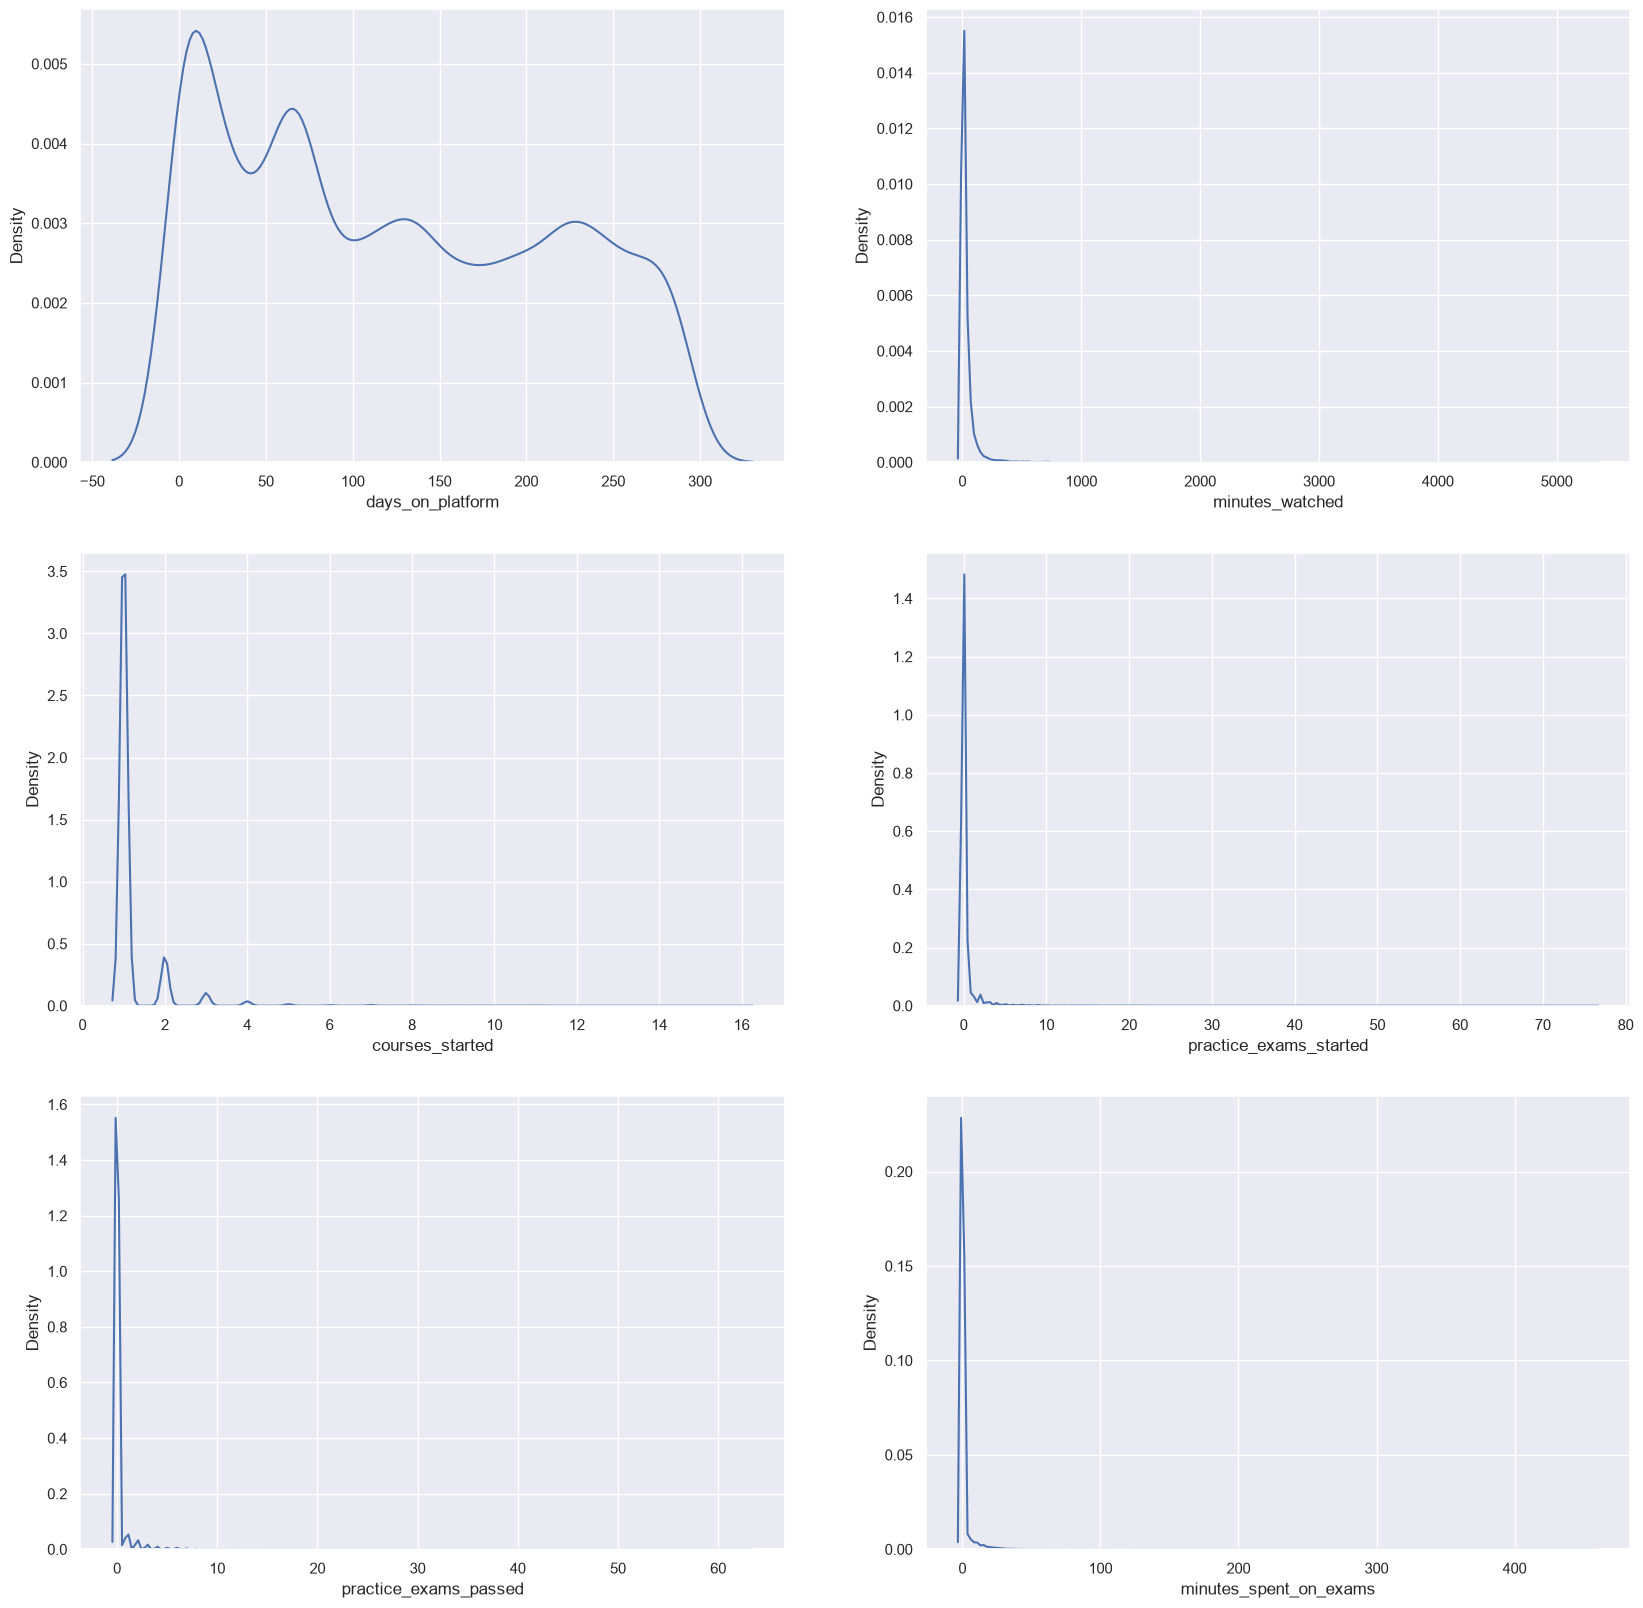

In [6]:
sns.set()
num_cols = ['days_on_platform', 'minutes_watched', 'courses_started',
            'practice_exams_started', 'practice_exams_passed', 'minutes_spent_on_exams']

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
for ax, col in zip(axes.flatten(), num_cols):
    sns.kdeplot(data=data[col], ax=ax)
plt.show()

In [7]:
data_no_outliers = data[(data['minutes_watched'] <= 1000) &
                        (data['courses_started'] <= 10) &
                        (data['practice_exams_started'] <= 10) &
                        (data['minutes_spent_on_exams'] <= 40)]

In [8]:
print(len(data), len(data_no_outliers))
print(data['purchased'].sum(), data_no_outliers['purchased'].sum())

17761 17626
1631 1624


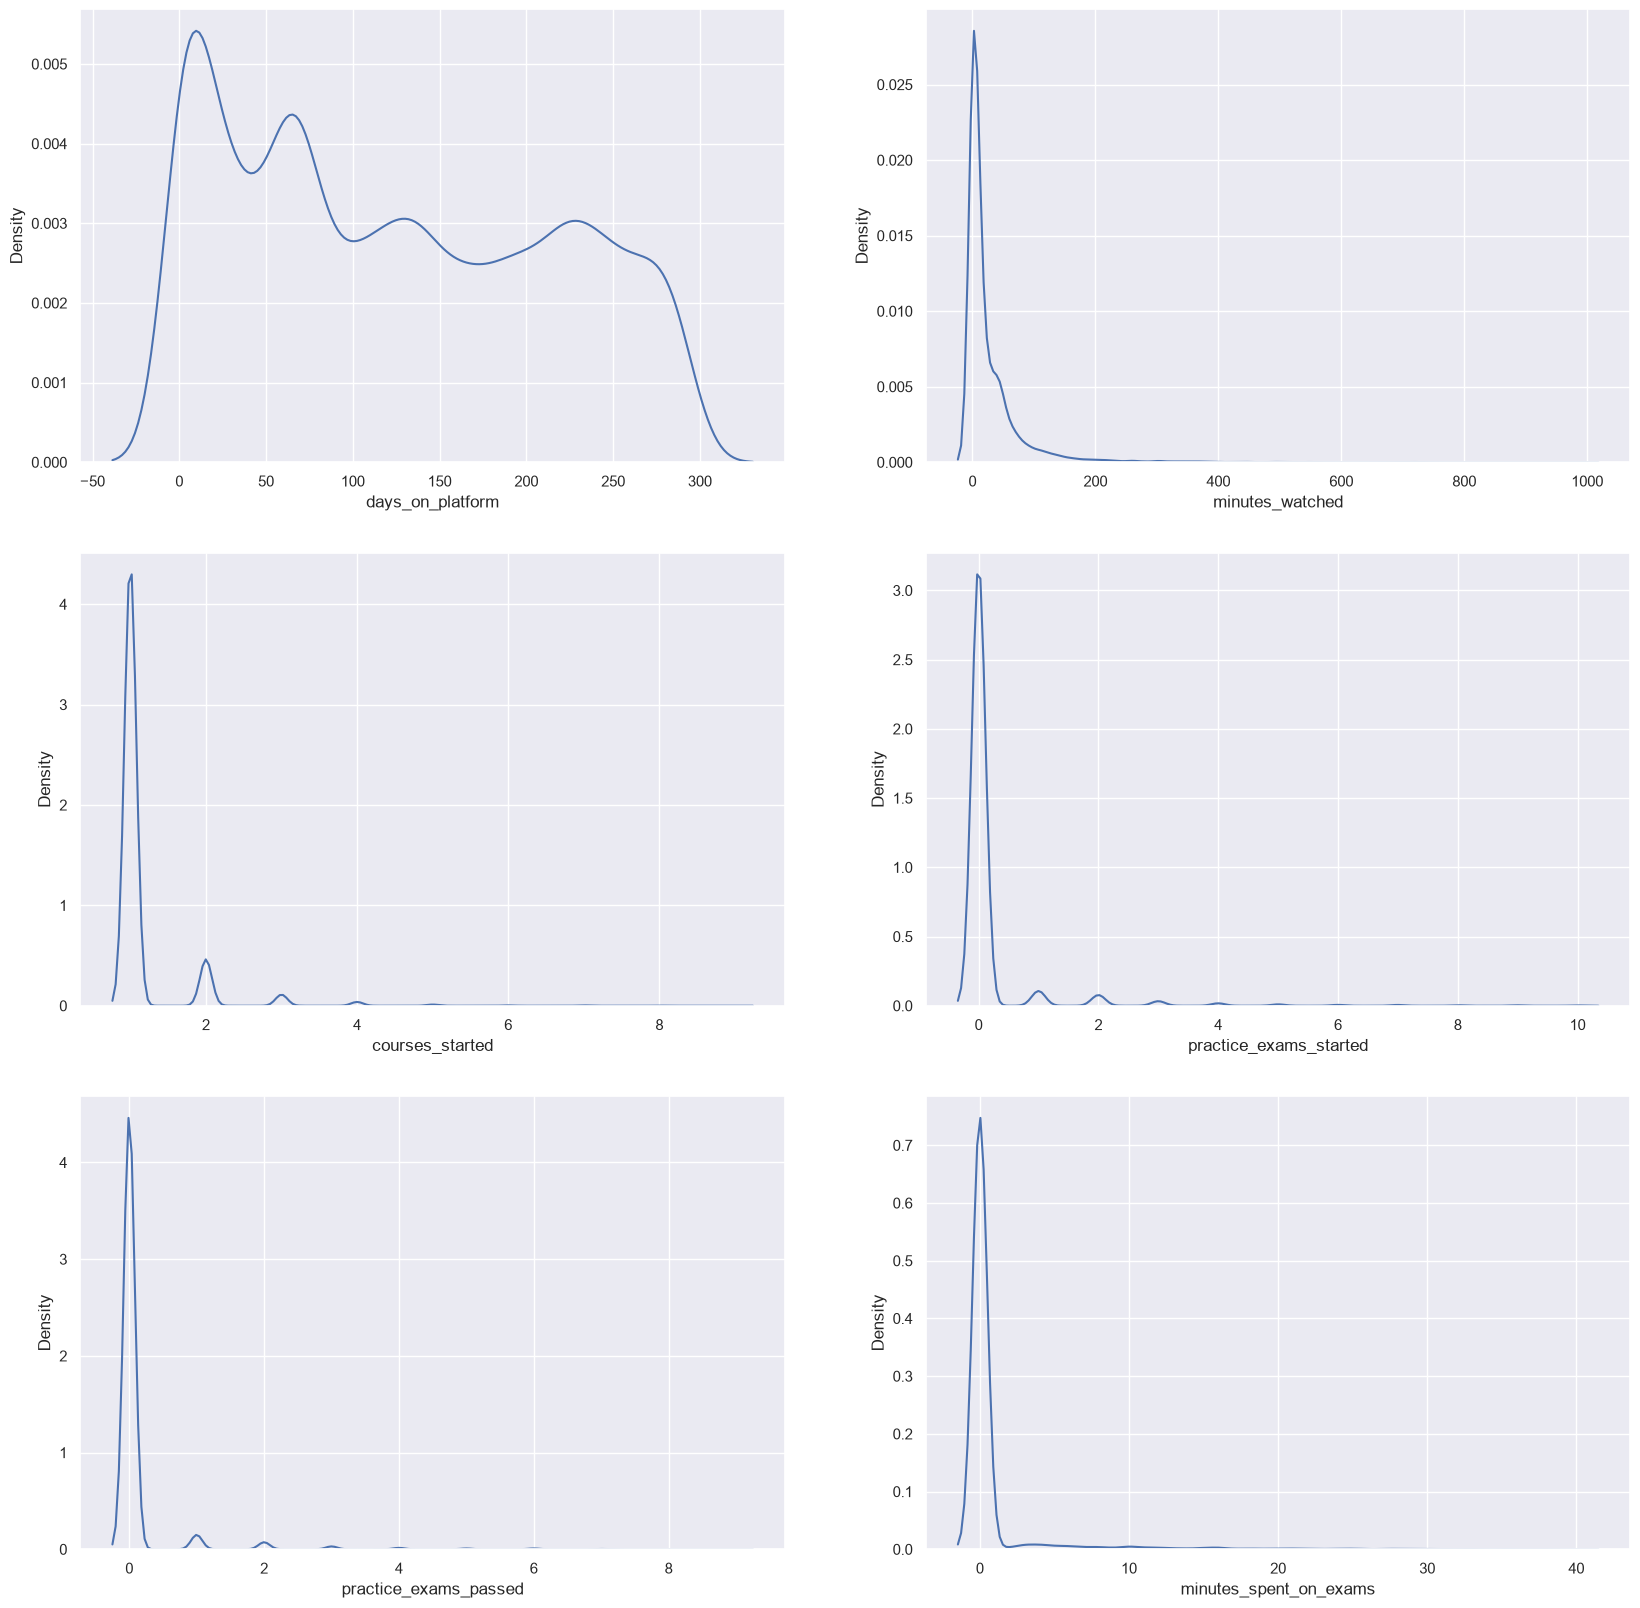

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(20, 20))
for ax, col in zip(axes.flatten(), num_cols):
    sns.kdeplot(data=data_no_outliers[col], ax=ax)
plt.show()

### Checking for Multicollinearity

In [10]:
def calc_vif(df, cols):
    return pd.Series([variance_inflation_factor(df[cols].values, i)
                      for i in range(len(cols))], index=cols)

calc_vif(data_no_outliers, num_cols)

days_on_platform          1.026055
minutes_watched           1.526461
courses_started           1.363355
practice_exams_started    9.731895
practice_exams_passed     7.505868
minutes_spent_on_exams    3.190319
dtype: float64

In [11]:
data_no_mult = data_no_outliers.drop('practice_exams_started', axis=1)

num_cols_2 = [c for c in num_cols if c != 'practice_exams_started']
calc_vif(data_no_mult, num_cols_2)

days_on_platform          1.024319
minutes_watched           1.525433
courses_started           1.363255
practice_exams_passed     2.474077
minutes_spent_on_exams    2.479652
dtype: float64

### Dealing with NaN Values

In [12]:
data_no_mult.isnull().sum()

student_country           8
days_on_platform          0
minutes_watched           0
courses_started           0
practice_exams_passed     0
minutes_spent_on_exams    0
purchased                 0
dtype: int64

In [13]:
data_no_mult.loc[data_no_mult['student_country'].isna()]

,student_country,days_on_platform,minutes_watched,courses_started,practice_exams_passed,minutes_spent_on_exams,purchased
311,NaN,88,58.1,1,2,11.20,1
337,NaN,86,43.0,1,2,12.96,0
556,NaN,121,241.9,2,3,21.29,0
806,NaN,64,86.4,1,2,4.98,0
1097,NaN,72,67.5,1,1,6.27,0
12363,NaN,84,6.2,1,0,0.00,0
12633,NaN,78,3.0,1,0,0.00,0
16946,NaN,11,8.2,1,0,0.00,0


In [14]:
data_no_nulls = data_no_mult.fillna({'student_country': 'NAM'})
data_no_nulls.isnull().sum()

student_country           0
days_on_platform          0
minutes_watched           0
courses_started           0
practice_exams_passed     0
minutes_spent_on_exams    0
purchased                 0
dtype: int64

In [15]:
data_no_nulls.loc[[311, 337, 556], 'student_country']

311    NAM
337    NAM
556    NAM
Name: student_country, dtype: str

### Splitting the Data

In [16]:
inputs = data_no_nulls.drop('purchased', axis=1)
targets = data_no_nulls['purchased']

x_train, x_test, y_train, y_test = train_test_split(
    inputs, targets, test_size=0.2, random_state=365, stratify=targets)

print(y_train.mean(), y_test.mean())
print(len(x_train), len(x_test))

0.09212765957446808 0.0921724333522405
14100 3526


### Encoding the Data

In [17]:
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=170)

x_train['student_country_enc'] = enc.fit_transform(x_train['student_country'].to_numpy().reshape(-1, 1))
x_test['student_country_enc'] = enc.transform(x_test['student_country'].to_numpy().reshape(-1, 1))

x_train = x_train.drop('student_country', axis=1)
x_test = x_test.drop('student_country', axis=1)

In [18]:
x_train.head()
x_train['student_country_enc'].max()

np.float64(162.0)

In [19]:
x_train_array = np.asarray(x_train, dtype='float')
y_train_array = np.asarray(y_train, dtype='int')
x_test_array = np.asarray(x_test, dtype='float')
y_test_array = np.asarray(y_test, dtype='int')

In [20]:
print(x_train_array.shape, x_test_array.shape)

(14100, 6) (3526, 6)


# Creating a Logistic Regression Model

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [22]:
log_reg = LogisticRegression()
log_reg.fit(x_train_array, y_train_array)

y_pred_lr = log_reg.predict(x_test_array)

print("Accuracy:", accuracy_score(y_test_array, y_pred_lr))
print(confusion_matrix(y_test_array, y_pred_lr))
print(classification_report(y_test_array, y_pred_lr))

Accuracy: 0.9503686897334089
[[3159   42]
 [ 133  192]]
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      3201
           1       0.82      0.59      0.69       325

    accuracy                           0.95      3526
   macro avg       0.89      0.79      0.83      3526
weighted avg       0.95      0.95      0.95      3526



# Creating a K-Nearest Neighbors Model

In [23]:
from sklearn.neighbors import KNeighborsClassifier

In [24]:
knn = KNeighborsClassifier()
knn.fit(x_train_array, y_train_array)

y_pred_knn = knn.predict(x_test_array)

print("Accuracy:", accuracy_score(y_test_array, y_pred_knn))
print(confusion_matrix(y_test_array, y_pred_knn))
print(classification_report(y_test_array, y_pred_knn))

Accuracy: 0.9591605218377766
[[3142   59]
 [  85  240]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      3201
           1       0.80      0.74      0.77       325

    accuracy                           0.96      3526
   macro avg       0.89      0.86      0.87      3526
weighted avg       0.96      0.96      0.96      3526



# Creating a Support Vector Machines Model

In [25]:
from sklearn.svm import SVC

In [26]:
svm = SVC()
svm.fit(x_train_array, y_train_array)

y_pred_svm = svm.predict(x_test_array)

print("Accuracy:", accuracy_score(y_test_array, y_pred_svm))
print(confusion_matrix(y_test_array, y_pred_svm))
print(classification_report(y_test_array, y_pred_svm))

Accuracy: 0.9557572319909245
[[3153   48]
 [ 108  217]]
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      3201
           1       0.82      0.67      0.74       325

    accuracy                           0.96      3526
   macro avg       0.89      0.83      0.86      3526
weighted avg       0.95      0.96      0.95      3526



# Creating a Decision Trees Model

In [27]:
from sklearn.tree import DecisionTreeClassifier

In [28]:
tree = DecisionTreeClassifier(random_state=365)
tree.fit(x_train_array, y_train_array)

y_pred_tree = tree.predict(x_test_array)

print("Accuracy:", accuracy_score(y_test_array, y_pred_tree))
print(confusion_matrix(y_test_array, y_pred_tree))
print(classification_report(y_test_array, y_pred_tree))

Accuracy: 0.9461145774248441
[[3102   99]
 [  91  234]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      3201
           1       0.70      0.72      0.71       325

    accuracy                           0.95      3526
   macro avg       0.84      0.84      0.84      3526
weighted avg       0.95      0.95      0.95      3526



# Creating a Random Forests Model

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
forest = RandomForestClassifier(random_state=365)
forest.fit(x_train_array, y_train_array)

y_pred_rf = forest.predict(x_test_array)

print("Accuracy:", accuracy_score(y_test_array, y_pred_rf))
print(confusion_matrix(y_test_array, y_pred_rf))
print(classification_report(y_test_array, y_pred_rf))

Accuracy: 0.9602949517867272
[[3145   56]
 [  84  241]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      3201
           1       0.81      0.74      0.77       325

    accuracy                           0.96      3526
   macro avg       0.89      0.86      0.88      3526
weighted avg       0.96      0.96      0.96      3526



In [31]:
import statsmodels.api as sm

x_train_const = sm.add_constant(x_train_array)
logit = sm.Logit(y_train_array, x_train_const).fit()
logit.summary(xname=['const'] + list(x_train.columns))

Optimization terminated successfully.
         Current function value: 0.150289
         Iterations 10


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                14100
Model:                          Logit   Df Residuals:                    14093
Method:                           MLE   Df Model:                            6
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.5111
Time:                        17:27:31   Log-Likelihood:                -2119.1
converged:                       True   LL-Null:                       -4334.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -1.0543      0.118     -8.961      0.000      -1.285      -0.824
days_on_platform          -0.0666      0.002    -30.565      0.000      -0.071      -0.062
minutes_watched            0.0127      0.001     17.761      0.000       0.011       0.014
courses_started            0.1971      0.079      2.496      0.013       0.042       0.352
practice_exams_passed      0.1226      0.077      1.600      0.110      -0.028       0.273
minutes_spent_on_exams    -0.0724      0.016     -4.568      0.000      -0.103      -0.041
student_country_enc        0.0070      0.001      8.619      0.000       0.005       0.009
==========================================================================================

Possibly complete quasi-separation: A fraction 0.43 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [32]:
cols_sig = [c for c in x_train.columns if c != 'practice_exams_passed']
x_train_sig = sm.add_constant(x_train[cols_sig].astype(float))

logit_sig = sm.Logit(y_train_array, x_train_sig).fit()
logit_sig.summary()

Optimization terminated successfully.
         Current function value: 0.150382
         Iterations 10


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                14100
Model:                          Logit   Df Residuals:                    14094
Method:                           MLE   Df Model:                            5
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.5108
Time:                        17:27:32   Log-Likelihood:                -2120.4
converged:                       True   LL-Null:                       -4334.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -1.0423      0.117     -8.891      0.000      -1.272      -0.813
days_on_platform          -0.0667      0.002    -30.571      0.000      -0.071      -0.062
minutes_watched            0.0129      0.001     18.163      0.000       0.012       0.014
courses_started            0.1866      0.078      2.379      0.017       0.033       0.340
minutes_spent_on_exams    -0.0542      0.011     -5.116      0.000      -0.075      -0.033
student_country_enc        0.0070      0.001      8.622      0.000       0.005       0.009
==========================================================================================

Possibly complete quasi-separation: A fraction 0.43 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [33]:
from sklearn.model_selection import GridSearchCV

knn_grid = GridSearchCV(KNeighborsClassifier(),
                        {'n_neighbors': [7, 10], 'weights': ['uniform', 'distance']},
                        cv=5, scoring='accuracy').fit(x_train_array, y_train_array)
print(knn_grid.best_params_)

tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=365),
                         {'ccp_alpha': [0, 0.001, 0.002, 0.003, 0.004, 0.005]},
                         cv=5, scoring='accuracy').fit(x_train_array, y_train_array)
print(tree_grid.best_params_)

{'n_neighbors': 10, 'weights': 'distance'}
{'ccp_alpha': 0.001}
